# American Options: Longstaff–Schwartz vs Deep Optimal Stopping

An option that can be exercised early is hard to price by simulation, because the decision to exercise depends on what the option would be worth if kept, and that is itself unknown. The industry answer since 2001 is a regression trick; a newer answer lets a neural network learn the exercise decision directly. This notebook compares the two against exact benchmarks, from one asset to many.

**What it does.** It prices early-exercise options by Monte Carlo two ways: the industry-standard Longstaff–Schwartz regression (LSM), and Deep Optimal Stopping (DOS), where a neural network learns the exercise decision directly.

One case is a classic American put, checked against an exact Bermudan binomial tree. The other is a multi-asset Bermudan max-call, checked against published reference values.

**Data.** Synthetic, under standard textbook parameters, so every number can be checked against known benchmarks.

**Methods.** A CRR binomial tree with exercise restricted to the Bermudan dates, LSM with polynomial and payoff basis functions, and DOS (Becker, Cheridito & Jentzen, 2019) with one sigmoid network per exercise date, trained by backward induction in PyTorch. Lower bounds are measured out of sample on independent paths with confidence intervals.

**Key output.** Prices and errors against benchmarks, the learned exercise boundary of the put, and accuracy against compute time as the number of assets grows.

## 1. Early exercise and why it is hard for Monte Carlo

An American or Bermudan option is worth $\sup_\tau \mathbb E[e^{-r\tau}g(X_\tau)]$ over stopping times $\tau$. Monte Carlo simulates forward, but the exercise decision depends on the **continuation value**, which is an expectation conditional on the path so far. Two answers:

- **LSM** (Longstaff & Schwartz, 2001) estimates the continuation value at each date by regressing discounted future cash flows on basis functions of the state, then exercises when the payoff exceeds it. It is fast and robust in low dimension, but the number of basis functions grows quickly with the number of assets.
- **DOS** (Becker, Cheridito & Jentzen, 2019) skips the continuation value: at each date $n$ a network $f_n(x)\in(0,1)$ is trained to **maximise** $\mathbb E\big[g(X_n)f_n(X_n)+g(X_{\tau_{n+1}})(1-f_n(X_n))\big]$, the expected payoff of "stop now with probability $f_n$, otherwise follow the later rule". The hard rule $\mathbb 1\{f_n\ge \tfrac12\}$ is then applied.

Both give **lower bounds** when the learned rule is applied to fresh paths, since any rule is sub-optimal. The benchmark tells us how close they get.

For a credit and counterparty risk function, early exercise matters because callable bonds, Bermudan swaptions and cancellable swaps are common in MDB funding and hedging. Their exposure profiles depend on the exercise policy.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 23
N_TRAIN = 100_000  # paths used to learn the exercise rule
# independent paths to price with the learned rule (unbiased lower bound)
N_PRICE = 200_000
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(f"torch {torch.__version__} · run on {dt.date.today():%Y-%m-%d}")

torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


METHOD_COLORS = {
    "Binomial (exact)": INK_2,
    "LSM": PALETTE[0],
    "DOS": PALETTE[1],
}

## 3. The two engines

Paths are geometric Brownian motions with dividend yield $\delta$, simulated exactly at the exercise dates. Both methods share the same training paths and are priced on the same independent pricing paths.

In [3]:
def gbm(n, d, S0, r, delta, sigma, T, n_dates, seed, corr=0.0):
    rng = np.random.default_rng(seed)
    dt = T / n_dates
    C = np.full((d, d), corr) + (1 - corr) * np.eye(d)
    L = np.linalg.cholesky(C)
    z = rng.standard_normal((n, n_dates, d)) @ L.T
    logS = np.log(S0) + np.cumsum(
        (r - delta - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z, axis=1
    )
    # n × (dates+1) × d
    return np.concatenate(
        [np.full((n, 1, d), float(S0)), np.exp(logS)], axis=1
    )


def basis(X, payoff, degree=2):
    """
    Polynomial basis in the (normalised) assets up to `degree`, plus the payoff
    itself.
    """
    n, d = X.shape
    cols = [np.ones(n), payoff]
    cols += [X[:, i] for i in range(d)]
    if degree >= 2:
        cols += [X[:, i] * X[:, j] for i in range(d) for j in range(i, d)]
    if degree >= 3 and d == 1:
        cols += [X[:, 0] ** 3]
    return np.column_stack(cols)


def lsm_fit(paths, payoff_fn, r, dt, scale, degree=2):
    """
    Backward induction; regressions on in-the-money paths only. Returns
    coefficients per date.
    """
    n, N1, _ = paths.shape
    cash = payoff_fn(paths[:, -1])
    coefs = {}
    for t in range(N1 - 2, 0, -1):
        cash *= np.exp(-r * dt)
        g = payoff_fn(paths[:, t])
        itm = g > 0
        if itm.sum() < 50:
            continue
        A = basis(paths[itm, t] / scale, g[itm] / scale, degree)
        beta = np.linalg.lstsq(A, cash[itm] / scale, rcond=None)[0]
        coefs[t] = beta
        cont = A @ beta * scale
        ex = g[itm] > cont
        idx = np.flatnonzero(itm)[ex]
        cash[idx] = g[itm][ex]
    return coefs


def lsm_price(paths, payoff_fn, r, dt, scale, coefs, degree=2):
    n, N1, _ = paths.shape
    value, alive = np.zeros(n), np.ones(n, bool)
    for t in range(1, N1):
        g = payoff_fn(paths[:, t])
        if t == N1 - 1:
            stop = alive & (g > 0)
        elif t in coefs:
            itm = alive & (g > 0)
            cont = np.full(n, np.inf)
            cont[itm] = (
                basis(paths[itm, t] / scale, g[itm] / scale, degree)
                @ coefs[t]
                * scale
            )
            stop = itm & (g > cont)
        else:
            stop = np.zeros(n, bool)
        value[stop] = np.exp(-r * dt * t) * g[stop]
        alive &= ~stop
    return value.mean(), value.std() / np.sqrt(n)


class StopNet(torch.nn.Module):
    def __init__(self, d, width):
        super().__init__()
        self.f = torch.nn.Sequential(
            torch.nn.Linear(d + 1, width),
            torch.nn.BatchNorm1d(width),
            torch.nn.ReLU(),
            torch.nn.Linear(width, width),
            torch.nn.BatchNorm1d(width),
            torch.nn.ReLU(),
            torch.nn.Linear(width, 1),
        )

    def forward(self, x):
        return torch.sigmoid(self.f(x)).squeeze(-1)


def dos_features(Xt, g, scale):
    return torch.tensor(
        np.column_stack([Xt / scale, g / scale]), dtype=torch.float32
    )


def dos_fit(paths, payoff_fn, r, dt, scale, steps=600, batch=4096, width=None):
    """
    Becker–Cheridito–Jentzen: one network per date, trained backward to
    maximise expected payoff.
    """
    n, N1, d = paths.shape
    width = width or d + 40
    disc_g = (
        np.stack(
            [np.exp(-r * dt * t) * payoff_fn(paths[:, t]) for t in range(N1)],
            axis=1,
        )
        / scale
    )
    # discounted payoff of the rule from t+1 onwards
    stop_val = disc_g[:, -1].copy()
    nets = {}
    for t in range(N1 - 2, 0, -1):
        net = StopNet(d, width)
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
        Xf = dos_features(paths[:, t], payoff_fn(paths[:, t]), scale)
        gnow, gcont = torch.tensor(
            disc_g[:, t], dtype=torch.float32
        ), torch.tensor(stop_val, dtype=torch.float32)
        for _ in range(steps):
            b = torch.randint(0, n, (batch,))
            f = net(Xf[b])
            loss = -torch.mean(gnow[b] * f + gcont[b] * (1 - f))
            opt.zero_grad()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            stop = (net(Xf) >= 0.5).numpy() & (disc_g[:, t] > 0)
        stop_val = np.where(stop, disc_g[:, t], stop_val)
        nets[t] = net
    return nets


def dos_price(paths, payoff_fn, r, dt, scale, nets):
    n, N1, _ = paths.shape
    value, alive = np.zeros(n), np.ones(n, bool)
    for t in range(1, N1):
        g = payoff_fn(paths[:, t])
        if t == N1 - 1:
            stop = alive & (g > 0)
        else:
            with torch.no_grad():
                stop = (
                    alive
                    & (
                        nets[t](dos_features(paths[:, t], g, scale)).numpy()
                        >= 0.5
                    )
                    & (g > 0)
                )
        value[stop] = np.exp(-r * dt * t) * g[stop]
        alive &= ~stop
    return value.mean(), value.std() / np.sqrt(n)

## 4. Case 1: Bermudan put on one asset

The Longstaff–Schwartz test case: strike 40, rate 6%, no dividends, exercise 50 times a year, spot 36–44, volatility 20% or 40%, maturity 1 or 2 years. The benchmark is a **CRR binomial tree** with 5,000 steps per year in which exercise is allowed **only on the 50 Bermudan dates**, the exact Bermudan price up to tree error.

LSM uses a cubic polynomial in $S$ plus the payoff; DOS uses a small network on $(S/K, g/K)$.

In [4]:
K_PUT, R_PUT = 40.0, 0.06


def binomial_bermudan_put(
    S0, K, r, sigma, T, ex_per_year=50, steps_per_year=5_000
):
    N = int(steps_per_year * T)
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d_ = 1 / u
    p = (np.exp(r * dt) - d_) / (u - d_)
    disc = np.exp(-r * dt)
    ex_every = steps_per_year // ex_per_year
    S = S0 * u ** np.arange(N, -N - 1, -2)
    V = np.maximum(K - S, 0)
    for i in range(N - 1, -1, -1):
        S = S0 * u ** np.arange(i, -i - 1, -2)
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if i % ex_every == 0 and i > 0:
            V = np.maximum(V, K - S)
    return V[0]


put_payoff = lambda X: np.maximum(K_PUT - X[:, 0], 0)
rows, boundary = [], {}
t0 = time.perf_counter()
for S0 in (36, 40, 44):
    for sigma, T in [(0.2, 1), (0.4, 1), (0.2, 2)]:
        n_dates = int(50 * T)
        dt = T / n_dates
        tr = gbm(N_TRAIN, 1, S0, R_PUT, 0.0, sigma, T, n_dates, seed=SEED + S0)
        te = gbm(
            N_PRICE,
            1,
            S0,
            R_PUT,
            0.0,
            sigma,
            T,
            n_dates,
            seed=SEED + 1000 + S0,
        )
        t1 = time.perf_counter()
        coefs = lsm_fit(tr, put_payoff, R_PUT, dt, K_PUT, degree=3)
        lsm_p, lsm_se = lsm_price(
            te, put_payoff, R_PUT, dt, K_PUT, coefs, degree=3
        )
        t_lsm = time.perf_counter() - t1
        t1 = time.perf_counter()
        nets = dos_fit(
            tr, put_payoff, R_PUT, dt, K_PUT, steps=200, batch=2048, width=32
        )
        dos_p, dos_se = dos_price(te, put_payoff, R_PUT, dt, K_PUT, nets)
        t_dos = time.perf_counter() - t1
        bench = binomial_bermudan_put(S0, K_PUT, R_PUT, sigma, T)
        euro = float(
            stats.norm.cdf(
                -(np.log(S0 / K_PUT) + (R_PUT - 0.5 * sigma**2) * T)
                / (sigma * np.sqrt(T))
            )
            * K_PUT
            * np.exp(-R_PUT * T)
            - S0
            * stats.norm.cdf(
                -(np.log(S0 / K_PUT) + (R_PUT + 0.5 * sigma**2) * T)
                / (sigma * np.sqrt(T))
            )
        )
        rows.append({
            "S0": S0,
            "sigma": sigma,
            "T": T,
            "European (BS)": euro,
            "Bermudan binomial": bench,
            "LSM": lsm_p,
            "LSM s.e.": lsm_se,
            "DOS": dos_p,
            "DOS s.e.": dos_se,
            "LSM error": lsm_p - bench,
            "DOS error": dos_p - bench,
            "LSM s": t_lsm,
            "DOS s": t_dos,
        })
        if S0 == 36 and sigma == 0.2 and T == 1:
            boundary = {
                "nets": nets,
                "coefs": coefs,
                "dt": dt,
                "n_dates": n_dates,
            }
put_tbl = pd.DataFrame(rows)
print(
    f"9 put configurations in {time.perf_counter() - t0:.0f}s · mean |error|"
    f" LSM {put_tbl['LSM error'].abs().mean():.4f}, DOS"
    f" {put_tbl['DOS error'].abs().mean():.4f} (both are lower bounds; s.e. ≈"
    f" {put_tbl['LSM s.e.'].mean():.4f})"
)
put_tbl.round(4)

9 put configurations in 342s · mean |error| LSM 0.0058, DOS 0.0231 (both are lower bounds; s.e. ≈ 0.0085)


,S0,sigma,T,European (BS),Bermudan binomial,LSM,LSM s.e.,DOS,DOS s.e.,LSM error,DOS error,LSM s,DOS s
0,36,0.20,1,3.84,4.48,4.47,0.01,4.44,0.01,-0.01,-0.04,0.78,29.26
1,36,0.40,1,6.71,7.10,7.09,0.01,7.04,0.01,-0.01,-0.06,0.92,27.82
2,36,0.20,2,3.76,4.84,4.84,0.01,4.79,0.01,0.00,-0.05,1.51,54.00
3,40,0.20,1,2.07,2.31,2.31,0.01,2.30,0.01,-0.01,-0.01,0.84,27.01
4,40,0.40,1,5.06,5.31,5.30,0.01,5.29,0.01,-0.01,-0.02,1.07,26.53
5,40,0.20,2,2.36,2.88,2.88,0.01,2.86,0.01,-0.00,-0.02,1.68,55.63
6,44,0.20,1,1.02,1.11,1.11,0.00,1.11,0.00,-0.00,-0.00,0.45,24.88
7,44,0.40,1,3.78,3.95,3.96,0.01,3.95,0.01,0.01,-0.00,0.66,25.32
8,44,0.20,2,1.43,1.69,1.68,0.01,1.68,0.01,-0.01,-0.01,0.96,53.09


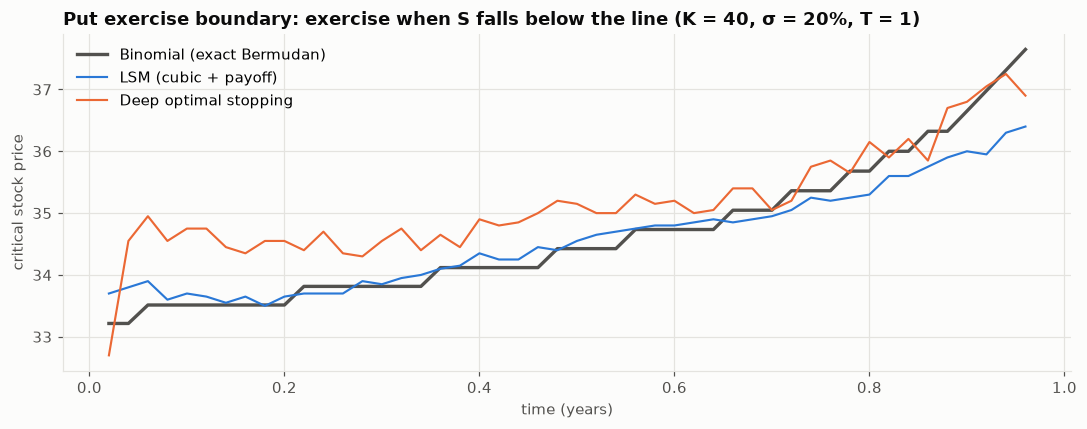

In [5]:
# --- Chart 1: the exercise boundaries the two methods learned (S0 = 36, σ =
# 20%, T = 1)
sigma, T = 0.2, 1
S_grid = np.linspace(20, 40, 401)
dates = range(1, boundary["n_dates"] - 1)
b_lsm, b_dos = [], []
for t in dates:
    g = np.maximum(K_PUT - S_grid, 0)
    if t in boundary["coefs"]:
        cont = (
            basis(S_grid[:, None] / K_PUT, g / K_PUT, 3)
            @ boundary["coefs"][t]
            * K_PUT
        )
        ex = (g > cont) & (g > 0)
        b_lsm.append(S_grid[ex].max() if ex.any() else np.nan)
    else:
        b_lsm.append(np.nan)
    with torch.no_grad():
        f = boundary["nets"][t](
            dos_features(S_grid[:, None], g, K_PUT)
        ).numpy()
    ex = (f >= 0.5) & (g > 0)
    b_dos.append(S_grid[ex].max() if ex.any() else np.nan)


def tree_boundary(K, r, sigma, T, steps_per_year=2_000, ex_per_year=50):
    """Critical price at each Bermudan date from the binomial tree."""
    N = int(steps_per_year * T)
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    p = (np.exp(r * dt) - 1 / u) / (u - 1 / u)
    disc = np.exp(-r * dt)
    every = steps_per_year // ex_per_year
    V = np.maximum(K - 36.0 * u ** np.arange(N, -N - 1, -2), 0)
    crit = {}
    for i in range(N - 1, -1, -1):
        S = 36.0 * u ** np.arange(i, -i - 1, -2)
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if i % every == 0 and i > 0:
            ex = (K - S) >= V
            crit[i // every] = S[ex].max() if ex.any() else np.nan
            V = np.maximum(V, K - S)
    return crit


crit = tree_boundary(K_PUT, R_PUT, sigma, T)
fig, ax = plt.subplots(figsize=(10, 4))
tt = np.array(list(dates)) * boundary["dt"]
ax.plot(
    tt,
    [crit.get(t, np.nan) for t in dates],
    color=INK_2,
    lw=2.2,
    label="Binomial (exact Bermudan)",
)
ax.plot(tt, b_lsm, color=PALETTE[0], lw=1.4, label="LSM (cubic + payoff)")
ax.plot(tt, b_dos, color=PALETTE[1], lw=1.4, label="Deep optimal stopping")
ax.set_title(
    "Put exercise boundary: exercise when S falls below the line (K = 40, σ ="
    " 20%, T = 1)"
)
ax.set_xlabel("time (years)")
ax.set_ylabel("critical stock price")
ax.legend()
plt.tight_layout()
save_fig(fig, "01_put_exercise_boundary")
plt.show()

## 5. Case 2: Bermudan max-call on 2 and 5 assets

The standard high-dimensional test (Broadie & Glasserman; Andersen & Broadie 2004; Becker, Cheridito & Jentzen 2019): payoff $\big(\max_i S^i - K\big)^+$ with $K=100$, $r=5\%$, dividend yield $\delta=10\%$, $\sigma=20\%$, independent assets, $T=3$ years, 9 exercise dates. The published reference values (consensus of primal–dual bounds in those papers) are:

| $d$ | $S_0=90$ | $S_0=100$ | $S_0=110$ |
|---|---|---|---|
| 2 | 8.07 | 13.90 | 21.34 |
| 5 | 16.64 | 26.16 | 36.77 |

LSM uses a second-order polynomial in all assets plus the payoff (6 terms for $d=2$, 22 for $d=5$). DOS uses networks with $d+40$ units per layer.

In [6]:
REF = {
    (2, 90): 8.07,
    (2, 100): 13.90,
    (2, 110): 21.34,
    (5, 90): 16.64,
    (5, 100): 26.16,
    (5, 110): 36.77,
}
K_MC, R_MC, DIV, SIG, T_MC, N_DATES = 100.0, 0.05, 0.10, 0.20, 3.0, 9
max_call = lambda X: np.maximum(X.max(axis=1) - K_MC, 0)
rows = []
t0 = time.perf_counter()
for d in (2, 5):
    for S0 in (90, 100, 110):
        dt = T_MC / N_DATES
        tr = gbm(
            N_TRAIN,
            d,
            S0,
            R_MC,
            DIV,
            SIG,
            T_MC,
            N_DATES,
            seed=SEED + d * 10 + S0,
        )
        te = gbm(
            N_PRICE,
            d,
            S0,
            R_MC,
            DIV,
            SIG,
            T_MC,
            N_DATES,
            seed=SEED + 5000 + d * 10 + S0,
        )
        t1 = time.perf_counter()
        coefs = lsm_fit(tr, max_call, R_MC, dt, K_MC, degree=2)
        lsm_p, lsm_se = lsm_price(
            te, max_call, R_MC, dt, K_MC, coefs, degree=2
        )
        t_lsm = time.perf_counter() - t1
        t1 = time.perf_counter()
        nets = dos_fit(tr, max_call, R_MC, dt, K_MC, steps=600, batch=4096)
        dos_p, dos_se = dos_price(te, max_call, R_MC, dt, K_MC, nets)
        t_dos = time.perf_counter() - t1
        rows.append({
            "assets": d,
            "S0": S0,
            "reference": REF[(d, S0)],
            "LSM": lsm_p,
            "LSM s.e.": lsm_se,
            "DOS": dos_p,
            "DOS s.e.": dos_se,
            "LSM vs ref %": (lsm_p / REF[(d, S0)] - 1) * 100,
            "DOS vs ref %": (dos_p / REF[(d, S0)] - 1) * 100,
            "LSM s": t_lsm,
            "DOS s": t_dos,
        })
maxcall = pd.DataFrame(rows)
print(f"6 max-call configurations in {time.perf_counter() - t0:.0f}s")
maxcall.round(3)

6 max-call configurations in 140s


,assets,S0,reference,LSM,LSM s.e.,DOS,DOS s.e.,LSM vs ref %,DOS vs ref %,LSM s,DOS s
0,2,90,8.07,8.06,0.03,8.05,0.03,-0.12,-0.21,0.53,20.04
1,2,100,13.90,13.82,0.04,13.82,0.03,-0.57,-0.54,0.70,20.50
2,2,110,21.34,21.26,0.04,21.29,0.04,-0.38,-0.25,0.86,20.06
3,5,90,16.64,16.57,0.04,16.59,0.04,-0.42,-0.32,3.48,21.90
4,5,100,26.16,26.09,0.04,26.09,0.04,-0.26,-0.27,3.24,20.75
5,5,110,36.77,36.57,0.05,36.65,0.05,-0.54,-0.34,4.24,21.82


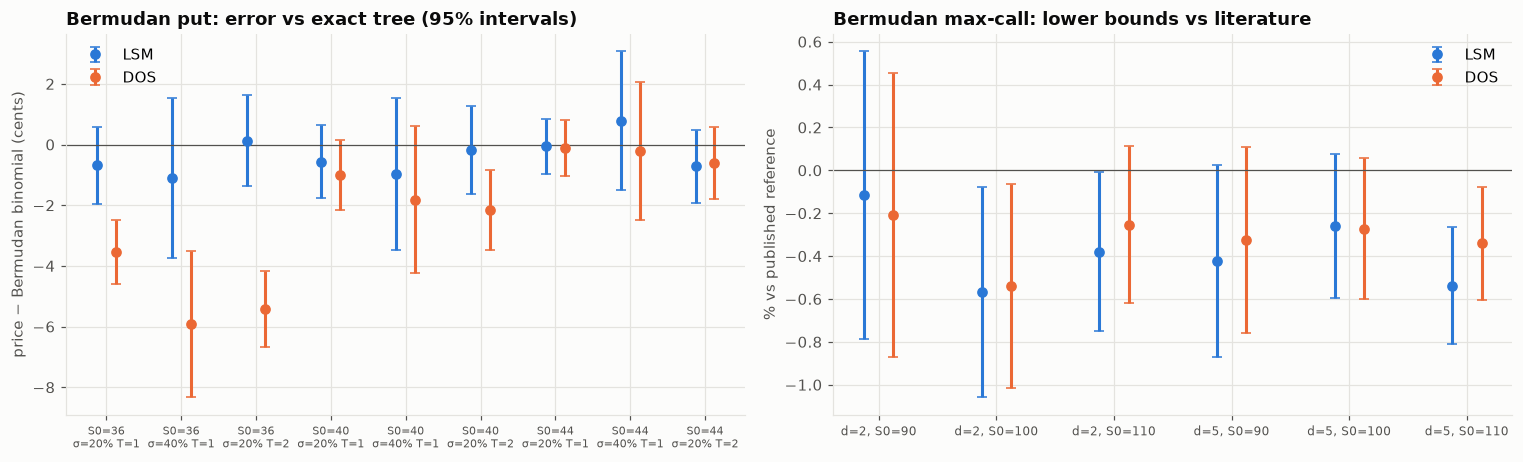

In [7]:
# --- Chart 2: accuracy against benchmarks
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
lab = [
    f"S0={int(r.S0)}\nσ={r.sigma:.0%} T={r.T}" for r in put_tbl.itertuples()
]
xp = np.arange(len(put_tbl))
for k, (m, color) in enumerate([("LSM", PALETTE[0]), ("DOS", PALETTE[1])]):
    ax.errorbar(
        xp + (k - 0.5) * 0.25,
        put_tbl[f"{m} error"] * 100,
        yerr=1.96 * put_tbl[f"{m} s.e."] * 100,
        fmt="o",
        color=color,
        capsize=3,
        label=m,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(xp, lab, fontsize=7)
ax.set_ylabel("price − Bermudan binomial (cents)")
ax.set_title("Bermudan put: error vs exact tree (95% intervals)")
ax.legend()
ax = axes[1]
lab = [f"d={int(r.assets)}, S0={int(r.S0)}" for r in maxcall.itertuples()]
xp = np.arange(len(maxcall))
for k, (m, color) in enumerate([("LSM", PALETTE[0]), ("DOS", PALETTE[1])]):
    ax.errorbar(
        xp + (k - 0.5) * 0.25,
        maxcall[f"{m} vs ref %"],
        yerr=1.96 * maxcall[f"{m} s.e."] / maxcall["reference"] * 100,
        fmt="o",
        color=color,
        capsize=3,
        label=m,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(xp, lab, fontsize=8)
ax.set_ylabel("% vs published reference")
ax.set_title("Bermudan max-call: lower bounds vs literature")
ax.legend()
plt.tight_layout()
save_fig(fig, "02_accuracy_vs_benchmarks")
plt.show()
put_tbl.to_csv(OUT_DIR / "bermudan_put_results.csv", index=False)
maxcall.to_csv(OUT_DIR / "bermudan_maxcall_results.csv", index=False)

## 6. Reading the results and limitations

- **The benchmark tree reproduces the classic numbers.** The Bermudan binomial prices (4.478, 7.102, 4.840 for S₀ = 36) match the finite-difference values in Longstaff & Schwartz's Table 1 to the third decimal, so the comparison is anchored.

**One asset: LSM wins clearly.** Its mean absolute error is 0.6 cents, within its own standard error (≈0.8 cents), and it runs in about 1 second. DOS undershoots by 2.3 cents on average and by up to 6 cents for in-the-money, long-dated puts, in 25–55 seconds.

The boundary chart shows why: DOS exercises too early (its boundary sits about $1 above the exact one for most of the option's life). With 50 exercise dates, each network gets little training and the errors accumulate backward. In one dimension a cubic regression is close to the true continuation value, and no neural network is needed.

**Max-call, 2 and 5 assets: the two methods are level.** Both lower bounds sit 0.1–0.6% below the published references, the expected sign for a lower bound. DOS is slightly closer for 5 assets at S₀ = 90 and 110 (−0.32% and −0.34% vs −0.42% and −0.54%) and slightly further for S₀ = 100.

With only 22 basis functions LSM is still competitive at d = 5, but the polynomial basis grows as $d^2$ (67 terms at d = 10, 232 at d = 20) while the network grows linearly. That growth is the regime the DOS paper targets.

- **Compute:** LSM takes 0.5–4 s and DOS about 20 s per configuration on CPU. For an exposure engine that must price Bermudans on every simulated path, LSM is the practical default. DOS becomes attractive for high-dimensional products or when the learned stopping rule is reused across many valuations.

**Limitations**

- Only lower bounds are computed. A dual upper bound (Andersen–Broadie, or the DOS paper's version) would bracket the price and certify the policy, at the cost of nested simulation.
- Training settings (paths, steps, widths) are modest so the notebook runs in minutes on a laptop CPU. The DOS paper trains far longer and reaches the references within a few cents.
- GBM only. For Bermudan swaptions the same methods apply to Hull–White paths, with swap values as basis functions or network inputs.

## References

### Finance and regulation

- Longstaff, F. A., & Schwartz, E. S. (2001). Valuing American options by simulation: A simple least-squares approach. *The Review of Financial Studies, 14*(1), 113–147. https://doi.org/10.1093/rfs/14.1.113
- Cox, J. C., Ross, S. A., & Rubinstein, M. (1979). Option pricing: A simplified approach. *Journal of Financial Economics, 7*(3), 229–263. https://doi.org/10.1016/0304-405X(79)90015-1
- Andersen, L., & Broadie, M. (2004). Primal-dual simulation algorithm for pricing multidimensional American options. *Management Science, 50*(9), 1222–1234. https://doi.org/10.1287/mnsc.1040.0258
- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1

### Machine learning and deep learning

- Becker, S., Cheridito, P., & Jentzen, A. (2019). Deep optimal stopping. *Journal of Machine Learning Research, 20*(74), 1–25. https://jmlr.org/papers/v20/18-232.html
- Becker, S., Cheridito, P., Jentzen, A., & Welti, T. (2021). Solving high-dimensional optimal stopping problems using deep learning. *European Journal of Applied Mathematics, 32*(3), 470–514. https://doi.org/10.1017/S0956792521000073
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703